<a href="https://colab.research.google.com/github/Valeria1100/Confiabilidad-y-planeaci-n-de-capacidad-de-un-servicio-de-inferencia-de-IA./blob/main/Punto%20A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# ==============================================================================
# CELDA 0: PARÁMETROS PERSONALIZADOS DEL GRUPO (Sección 3 y Entregable E1)
# ==============================================================================
# Integrantes Grupo 5:
# Pareja 1: Valeria Noreña (1013605786) + María Pachón (1014990415)
# Pareja 2: Thomas Bacca (1018436144) + Sara León (1016948827)

C1 = 1013605786 + 1014990415   # 2028596201
C2 = 1018436144 + 1016948827   # 2035384971
S = C1 + C2                    # 4063981172

# Única fuente de aleatoriedad permitida en todo el notebook
rng = np.random.default_rng(S)

# Parámetros derivados de S
tau = 180 + 10 * (S % 9)                      # 230 ms (Umbral SLO)
eps = 0.01 * (1 + (S % 3))                    # 0.03 (Proporción máxima tolerada L > tau)
conf_map = {0: 0.90, 1: 0.95, 2: 0.99}
confianza = conf_map[S % 3]                   # 0.99 (Nivel de confianza 1 - alpha)
alpha = 1.0 - confianza                       # 0.01 (Nivel de significancia)
g = 1.4 + 0.1 * (S % 7)                       # 2.0 (Factor de crecimiento proyección)
t1 = 180 + 10 * (S % 5)                       # 200 KB (Frontera tamaño pequeña/mediana)
t2 = 400 + 25 * (S % 5)                       # 450 KB (Frontera tamaño mediana/grande)
pi = (4 + (S % 6)) / 1000.0                   # 0.006 (Prevalencia incidentes)
k_max = 4 + (S % 5)                           # 6 (Máximo falsas alarmas/día)
r = S % 6                                     # 2 (Desplazamiento ítem B4)
N = 10 + (S % 11)                             # 19 (Solicitudes consecutivas ítem C4)

print(f"C1 = {C1} | C2 = {C2} | S = {S}")
print(f"tau = {tau} ms | eps = {eps} | 1-alpha = {confianza} | g = {g:.1f}")
print(f"t1 = {t1} KB | t2 = {t2} KB | pi = {pi} | k_max = {k_max} | r = {r} | N = {N}")

C1 = 2028596201 | C2 = 2035384971 | S = 4063981172
tau = 230 ms | eps = 0.03 | 1-alpha = 0.99 | g = 2.0
t1 = 200 KB | t2 = 450 KB | pi = 0.006 | k_max = 6 | r = 2 | N = 19


In [ ]:
# ==============================================================================
# PUNTO A1: AUDITORÍA Y PREPARACIÓN DE LOS DATOS
# ==============================================================================
df_raw = pd.read_csv('solicitudes.csv')
print(f"Total de registros crudos: {len(df_raw)}")

# 1. Detección y eliminación de registros duplicados exactos
n_dup = df_raw.duplicated(keep='first').sum()
df = df_raw.drop_duplicates(keep='first').copy()

# 2. Detección y corrección de error de escala en tam_kb (reportados en Bytes en vez de KB)
mask_bytes = df['tam_kb'] > 5000
n_bytes = mask_bytes.sum()
df.loc[mask_bytes, 'tam_kb'] = df.loc[mask_bytes, 'tam_kb'] / 1024.0

# 3. Tratamiento de valores faltantes (NaN) usando la arquitectura física (Sección 4.1)
n_nan_total = df.isna().any(axis=1).sum()
# Si cache_hit == 1, no usa GPU (gpu_ms = 0) y no hace cola (red_ms = latencia_ms)
mask_rec_gpu = (df['cache_hit'] == 1) & (df['gpu_ms'].isna())
mask_rec_red = (df['cache_hit'] == 1) & (df['red_ms'].isna())
df.loc[mask_rec_gpu, 'gpu_ms'] = 0.0
df.loc[mask_rec_red, 'red_ms'] = df.loc[mask_rec_red, 'latencia_ms']
# En cache_hit == 0, L = red + cola + G queda subdeterminada -> se excluyen
df = df.dropna(subset=['red_ms', 'gpu_ms']).copy()

# 4. Exclusión de latencias centinela negativas (latencia_ms == -1.0)
n_lat_neg = (df['latencia_ms'] <= 0).sum()
df = df[df['latencia_ms'] > 0].copy()

# 5. Exclusión de violaciones físicas donde L < red_ms + gpu_ms (tolerancia 0.02 ms por redondeo)
mask_fisica = df['latencia_ms'] + 0.02 < (df['red_ms'] + df['gpu_ms'])
n_fisica = mask_fisica.sum()
df = df[~mask_fisica].copy()

print(f"Duplicados eliminados: {n_dup}")
print(f"Tamaños corregidos (Bytes -> KB): {n_bytes}")
print(f"NaN reconstruidos (cache_hit=1): {mask_rec_gpu.sum() + mask_rec_red.sum()} | NaN excluidos (cache_hit=0): {n_nan_total - (mask_rec_gpu.sum() + mask_rec_red.sum())}")
print(f"Latencias centinela (<= 0) excluidas: {n_lat_neg}")
print(f"Violaciones físicas (L < red + G) excluidas: {n_fisica}")
print(f"Total de registros limpios conservados: {len(df)} ({len(df)/len(df_raw)*100:.2f}%)")

Total de registros crudos: 32472
Duplicados eliminados: 97
Tamaños corregidos (Bytes -> KB): 48
NaN reconstruidos (cache_hit=1): 24 | NaN excluidos (cache_hit=0): 40
Latencias centinela (<= 0) excluidas: 97
Violaciones físicas (L < red + G) excluidas: 64
Total de registros limpios conservados: 32174 (99.08%)


In [ ]:
# ==============================================================================
# PUNTO A2: ESTACIONARIEDAD, DETECCIÓN DE PUNTOS DE CAMBIO Y SENSIBILIDAD
# ==============================================================================
# 1. Prueba CUSUM con permutaciones de Montecarlo sobre bloques de 10 s (120 bloques)
df['bloque_10s'] = (df['t_llegada_s'] // 10).astype(int)
tasa_10s = df.groupby('bloque_10s')['id_solicitud'].count().reindex(range(120), fill_value=0).values / 10.0

cusum = np.cumsum(tasa_10s - np.mean(tasa_10s))
R_obs = np.max(cusum) - np.min(cusum)

R_perm = np.array([
    np.ptp(np.cumsum(rng.permutation(tasa_10s) - np.mean(tasa_10s)))
    for _ in range(5000)
])
p_cusum = np.mean(R_perm >= R_obs)
print(f"Prueba CUSUM global: R_obs = {R_obs:.2f}, p-valor = {p_cusum:.6f}")

# 2. Búsqueda óptima de puntos de cambio [ta, tb) mediante devianza Poisson en conteos de 1 s
df['sec'] = df['t_llegada_s'].astype(int)
conteos_1s = df.groupby('sec')['id_solicitud'].count().reindex(range(1200), fill_value=0).values

def poisson_deviance(y):
    m = np.mean(y)
    if len(y) == 0 or m == 0:
        return 0.0
    y_pos = y[y > 0]
    return 2.0 * (np.sum(y_pos * np.log(y_pos / m)) - np.sum(y) + len(y) * m)

best_dev = np.inf
ta_opt, tb_opt = None, None
for ta in range(350, 420):
    for tb in range(550, 620):
        seg_est = np.concatenate([conteos_1s[:ta], conteos_1s[tb:]])
        seg_ano = conteos_1s[ta:tb]
        dev = poisson_deviance(seg_est) + poisson_deviance(seg_ano)
        if dev < best_dev:
            best_dev = dev
            ta_opt, tb_opt = ta, tb

dev_null = poisson_deviance(conteos_1s)
print(f"Devianza 1 régimen: {dev_null:.2f} | Devianza 2 regímenes [{ta_opt}s, {tb_opt}s): {best_dev:.2f}")
print(f"Estadístico LRT (reducción devianza): {dev_null - best_dev:.2f}")

# 3. Verificación de equivalencia entre Pre-anomalía [0, 397) y Post-anomalía [577, 1200)
seg_pre = df[df['t_llegada_s'] < ta_opt]
seg_post = df[df['t_llegada_s'] >= tb_opt]

_, p_tasa = stats.mannwhitneyu(conteos_1s[:ta_opt], conteos_1s[tb_opt:])
ks_stat, p_ks = stats.ks_2samp(seg_pre['latencia_ms'], seg_post['latencia_ms'])

n1, k1 = len(seg_pre), (seg_pre['intentos'] > 1).sum()
n2, k2 = len(seg_post), (seg_post['intentos'] > 1).sum()
p_pool = (k1 + k2) / (n1 + n2)
z_reint = (k1/n1 - k2/n2) / np.sqrt(p_pool * (1 - p_pool) * (1/n1 + 1/n2))
p_reint = 2 * (1 - stats.norm.cdf(abs(z_reint)))

print(f"Equivalencia Pre vs Post -> Mann-Whitney tasa p={p_tasa:.4f} | KS latencia p={p_ks:.4f} | Z reintentos p={p_reint:.4f}")

# 4. Etiquetado definitivo del régimen estable y análisis de sensibilidad
df['regimen'] = np.where((df['t_llegada_s'] >= ta_opt) & (df['t_llegada_s'] < tb_opt),
                         'Inestable', 'Estable')
df_estable = df[df['regimen'] == 'Estable'].copy()
print(f"Solicitudes en Régimen Estable: {len(df_estable)} (duración = {ta_opt + (1200 - tb_opt)} s)")

Prueba CUSUM global: R_obs = 527.68, p-valor = 0.000000
Devianza 1 régimen: 6806.61 | Devianza 2 regímenes [397s, 576s): 1212.54
Estadístico LRT (reducción devianza): 5594.07
Equivalencia Pre vs Post -> Mann-Whitney tasa p=0.9940 | KS latencia p=0.9583 | Z reintentos p=0.1621
Solicitudes en Régimen Estable: 22040 (duración = 1021 s)


,Régimen,Versión,Variable,n,Media,Mediana,DE,IQR,Asimetría,Curtosis_exceso
0,Estable,A,latencia_ms,10963,66.022,52.00,49.141,57.950,2.020,6.691
1,Estable,A,gpu_ms,10963,35.530,23.50,45.146,52.230,2.314,9.137
2,Estable,A,red_ms,10963,26.438,26.40,3.918,5.260,0.005,0.024
3,Estable,A,tam_kb,10963,240.946,201.85,170.787,205.800,1.462,3.209
4,Estable,B,latencia_ms,11077,60.645,48.48,43.388,49.070,2.323,9.535
5,Estable,B,gpu_ms,11077,29.806,19.59,37.520,44.200,2.357,9.645
6,Estable,B,red_ms,11077,26.412,26.45,3.855,5.200,0.004,0.034
7,Estable,B,tam_kb,11077,239.108,200.04,169.048,205.380,1.434,2.959
8,Inestable,A,latencia_ms,5043,171.951,106.72,180.716,218.955,1.479,1.767
9,Inestable,A,gpu_ms,5043,34.329,23.04,41.958,51.780,1.964,5.645


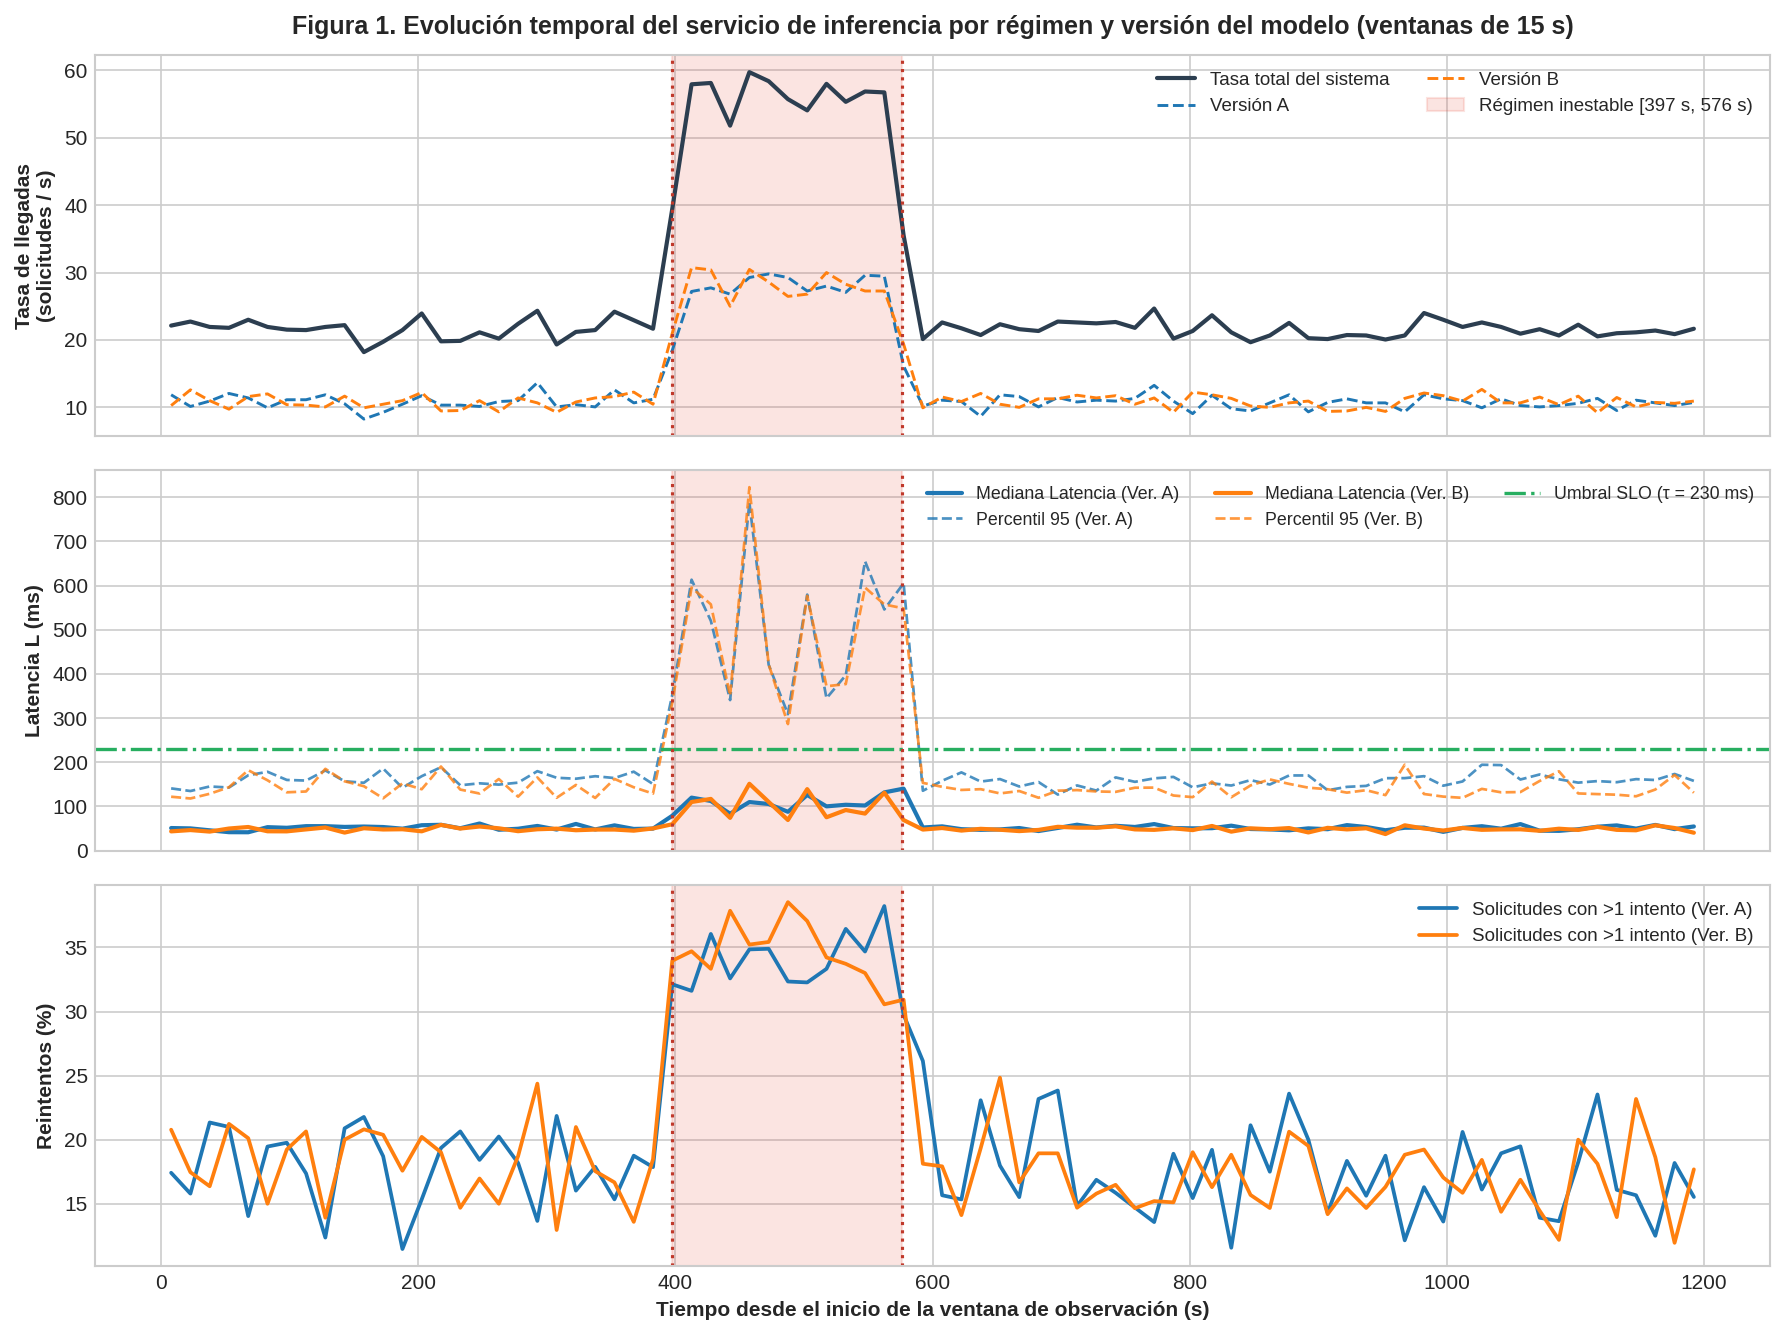

In [ ]:
# ==============================================================================
# PUNTO A3: ESTADÍSTICA DESCRIPTIVA Y FIGURA 1 (EVOLUCIÓN TEMPORAL)
# ==============================================================================
vars_interes = ['latencia_ms', 'gpu_ms', 'red_ms', 'tam_kb']
filas_a3 = []

for reg in ['Estable', 'Inestable']:
    for ver in ['A', 'B']:
        sub = df[(df['regimen'] == reg) & (df['version'] == ver)]
        for var in vars_interes:
            s = sub[var]
            filas_a3.append({
                'Régimen': reg,
                'Versión': ver,
                'Variable': var,
                'n': len(s),
                'Media': s.mean(),
                'Mediana': s.median(),
                'DE': s.std(ddof=1),
                'IQR': s.quantile(0.75) - s.quantile(0.25),
                'Asimetría': stats.skew(s, bias=False),
                'Curtosis_exceso': stats.kurtosis(s, fisher=True, bias=False)
            })

tabla_a3 = pd.DataFrame(filas_a3)
display(tabla_a3.round(3))

# Figura 1: Evolución temporal en ventanas de 15 s
df['v15'] = (df['t_llegada_s'] // 15).astype(int) * 15 + 7.5
ts = df.groupby(['v15', 'version']).agg(
    tasa=('id_solicitud', lambda x: len(x) / 15.0),
    lat_med=('latencia_ms', 'median'),
    lat_p95=('latencia_ms', lambda x: np.percentile(x, 95)),
    reint=('intentos', lambda x: (x > 1).mean() * 100)
).reset_index()
ts_tot = df.groupby('v15').agg(tasa_tot=('id_solicitud', lambda x: len(x) / 15.0)).reset_index()

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, dpi=150)
colores = {'A': '#1f77b4', 'B': '#ff7f0e'}

# Panel 1: Tasa de llegadas
axes[0].plot(ts_tot['v15'], ts_tot['tasa_tot'], color='#2c3e50', lw=2, label='Tasa total del sistema')
for ver in ['A', 'B']:
    sub_v = ts[ts['version'] == ver]
    axes[0].plot(sub_v['v15'], sub_v['tasa'], '--', lw=1.4, color=colores[ver], label=f'Versión {ver}')
axes[0].axvspan(ta_opt, tb_opt, color='#e74c3c', alpha=0.15, label=f'Régimen inestable [{ta_opt} s, {tb_opt} s)')
axes[0].axvline(ta_opt, color='#c0392b', ls=':', lw=1.5)
axes[0].axvline(tb_opt, color='#c0392b', ls=':', lw=1.5)
axes[0].set_ylabel('Tasa de llegadas\n(solicitudes / s)', fontsize=10, fontweight='bold')
axes[0].set_title('Figura 1. Evolución temporal del servicio de inferencia por régimen y versión del modelo (ventanas de 15 s)',
                  fontsize=12, fontweight='bold', pad=10)
axes[0].legend(loc='upper right', ncol=2, fontsize=9)

# Panel 2: Latencia mediana y P95
for ver in ['A', 'B']:
    sub_v = ts[ts['version'] == ver]
    axes[1].plot(sub_v['v15'], sub_v['lat_med'], lw=2, color=colores[ver], label=f'Mediana Latencia (Ver. {ver})')
    axes[1].plot(sub_v['v15'], sub_v['lat_p95'], '--', lw=1.3, color=colores[ver], alpha=0.8, label=f'Percentil 95 (Ver. {ver})')
axes[1].axhline(tau, color='#27ae60', ls='-.', lw=1.6, label=f'Umbral SLO (τ = {tau} ms)')
axes[1].axvspan(ta_opt, tb_opt, color='#e74c3c', alpha=0.15)
axes[1].axvline(ta_opt, color='#c0392b', ls=':', lw=1.5)
axes[1].axvline(tb_opt, color='#c0392b', ls=':', lw=1.5)
axes[1].set_ylabel('Latencia L (ms)', fontsize=10, fontweight='bold')
axes[1].legend(loc='upper right', ncol=3, fontsize=8.5)

# Panel 3: Reintentos
for ver in ['A', 'B']:
    sub_v = ts[ts['version'] == ver]
    axes[2].plot(sub_v['v15'], sub_v['reint'], lw=1.8, color=colores[ver], label=f'Solicitudes con >1 intento (Ver. {ver})')
axes[2].axvspan(ta_opt, tb_opt, color='#e74c3c', alpha=0.15)
axes[2].axvline(ta_opt, color='#c0392b', ls=':', lw=1.5)
axes[2].axvline(tb_opt, color='#c0392b', ls=':', lw=1.5)
axes[2].set_ylabel('Reintentos (%)', fontsize=10, fontweight='bold')
axes[2].set_xlabel('Tiempo desde el inicio de la ventana de observación (s)', fontsize=10, fontweight='bold')
axes[2].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('figura_1_evolucion_temporal.png', dpi=150)
plt.show()